# Evaluate Source Reconstruction Methods Using Simulations
Unfortunately, a true ground truth does not exist, which is why we need these source reconstruction methods in the first place. However, we can simulate data where we generate a ground truth. This allows us to compare how different methods reconstruct the data differently.

# Batch Wise Run

Run the code for a big number of simulation

## 📦 Imports

In [1]:
import mindmap as mm
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sp

# plot options
sns.set_theme(font_scale=1.5)
sns.set_style("whitegrid")

In [2]:
def compute_error(recon, area, src, brain, eeg, cras):
    """
    Compute source localisation at 50% rising phase and correlation at peak phase.

    Parameters
    ----------
    recon: mne.SourceEstimate.
        Reconstruction at 50% rising phase [0] and peak phase [1]

    area:
        Location of source. 

    src: mne.SourceSpace
        Dipole locations.

    brain:
        Ground truth.

    Returns
    -------
    dist: float
        Distance error to source location.

    corr: float
        Correlation with ground truth at peak phase.
    """

    # measure error distance
    estimate = mm.utils.select_source_estimate(recon, src, tp=0)
    dist = mm.utils.measure_distance(estimate, area, cras=cras)

    # measure correlation
    _, peak = mm.utils.eeg_rising_phase(eeg, 1)
    gt = np.abs(brain.data[:,peak])
    gt = (gt -gt.mean())/np.std(gt)

    tmp = np.abs(recon.data[:,1])
    tmp = (tmp - tmp.mean())/np.std(tmp)

    corr = np.sum(gt*tmp)/(gt.shape[0]-1)

    return dist, corr

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `fwd`: Forward operator
- `eeg`: Template EEG
- `sc`: Structural connectome
- `cst`: Connectome spectrum transform 
- `parc`: Parcellation 
- `ctx`: Cortical mask
- `cras`: Translation (FreeSurfer -> MRI)

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.

🛠️ **<font color=violet>Simulation options</font>**:
- `methods`: Names of source imaging methods 
- `N`: Number of different brain regions
- `rep`: Number of repetitions 

In [24]:
#################### Parameters ####################
# configuration
fconfig = "../../configurations/simf.yml"

# simulation
methods = ["cset", "sloreta"]
N       = "all"
rep     = 10
#####################################################

# configuration
config = mm.io.read_config("../../configurations/simf.yml")
sub    = config["SUBS"][0]

# data
data = mm.io.read_dataset(sub, "fwd", "eeg", "sc", "cst", "parc", "cras", "ctx")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- cst
- parc
- ctx
- cras
- sc
- fwd
- eeg
Missing objects:


## ♾️ Loop

In [25]:
error = {m:[] for m in methods}
error["loc"] = []

# select source locations
#source_regions = mm.utils.select_sources(sub, spacing="ico1", mask=data["ctx"], cras=data["cras"])
#source_regions = data["parc"].label_points(source_regions)
src    = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels = data["parc"].label_points(src)
labs   = np.unique(labels)

if N == "all":
    source_regions = labs 
else:
    source_regions = np.random.choice(labs, N, replace=False) 

# generate spike signal
spike = mm.utils.create_source_spike(
        duration = 1,                               # [s] 
        sfreq = data["eeg"].info["sfreq"],    # [Hz] 
        stype = "mex",                              # mexican hat signal 
        amplitude = 1e-8,                           # [A] (10-8 -> 10 [nA]) 
    )

# iterate through locations
for location in source_regions:
    
    area = data["parc"].create_mask(location)   # for localisation error

    spike_activity = mm.utils.generate_spike_activity(
        src      = data["fwd"]["src"],
        sc       = data["sc"],
        parc     = data["parc"],
        spike    = spike,
        location = location, 
        dw       = 0.25,        # propagation weight [0-1]
        dt       = 50,         # time delay [ms]
        sfreq    = data["eeg"].info["sfreq"],
        cras     = data["cras"],
    )

    # iterate through repetitions
    for r in range(rep):


        brain_noise, eeg_noise = mm.utils.generate_scaled_noise(
            data       = spike_activity,
            fwd        = data["fwd"],
            target_snr = 20,
            ratio      = 0.9, 
        )

        brain, eeg = mm.utils.simulate_eeg(
            brain_activity = spike_activity,
            fwd            = data["fwd"],
            eeg_temp       = data["eeg"],
            brain_noise    = brain_noise,
            eeg_noise      = eeg_noise, 
            sub            = sub,
        )

        # iterate through source reconstruction methods
        if "cset" in methods:
            recon = mm.cset(eeg=eeg, fwd=data["fwd"], cst=data["cst"], lam=0.1, dw=0.5, win_size=None, sub=sub)
            dist, corr = compute_error(recon, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
            error["cset"].append((dist,corr))
            
        if "sloreta" in methods:
            recon = mm.sloreta(eeg=eeg, fwd=data["fwd"], lam=0.01, win_size=None)
            dist, corr = compute_error(recon, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
            error["sloreta"].append((dist,corr))

        error["loc"].append(location)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projecti

## Visualize results

🌟 **Localization error**

Average difference:  6.666258238554193


WilcoxonResult(statistic=15917.0, pvalue=1.2101101750225149e-33)

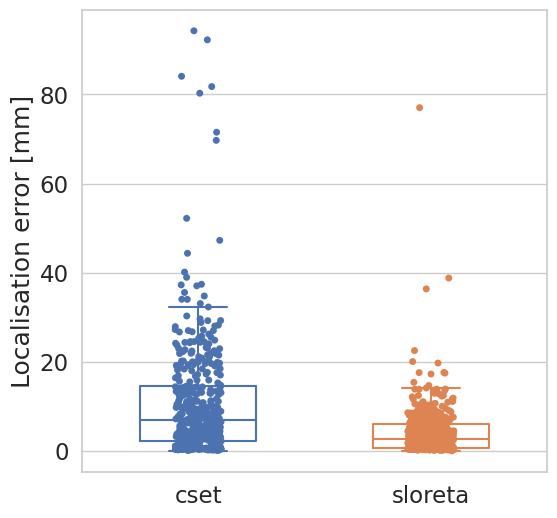

In [26]:
distance = error.copy()
for m in methods:
    distance[m] = [item[0] for item in distance[m]]

distance = pd.DataFrame(distance)
distance = distance.groupby("loc").mean()*1000

plt.figure(figsize=(6, 6))

ax  = sns.boxplot(data=distance, order=["cset", "sloreta"], fill=False, showfliers=False, width=0.5)
ax2 = sns.stripplot(data=distance, order=["cset", "sloreta"])

ax.set(ylabel="Localisation error [mm]")


print("Average difference: ", abs(distance["cset"].mean() - distance["sloreta"].mean()))
sp.stats.wilcoxon(distance["cset"].values, distance["sloreta"].values)

🌟 **Localization error by region** <br>
🛠️ **<font color=violet>Options</font>**:
- `method`: Which source imaging method to plot.


In [28]:
#################### Parameters ######################
method = "sloreta" 
######################################################

# source labels
src    = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels = np.array(data["parc"].label_points(src))

# associate each region to distance error
signal    = np.zeros(src.shape[0])
signal[:] = np.nan

for l, v in zip(distance.index, distance[method]):
    signal[labels == l] = v

# plot
mm.viz.plot_brain_signal(data["fwd"]["src"], signal, cmap="reds").show()

Widget(value='<iframe src="http://localhost:41891/index.html?ui=P_0x776c459c0c50_7&reconnect=auto" class="pyvi…

🌟 **Correlation**

Average difference: 0.10091308345596667


WilcoxonResult(statistic=5117.0, pvalue=1.3575027399369192e-60)

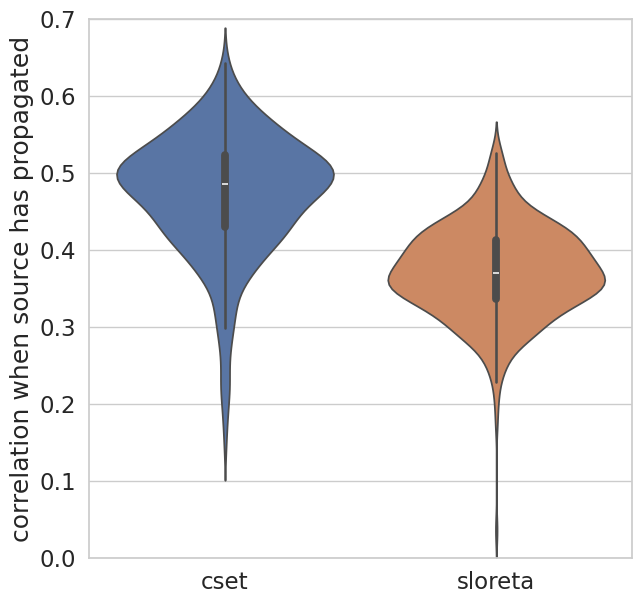

In [23]:
correlation = error.copy()
for m in methods:
    correlation[m] = [item[1] for item in correlation[m]]

correlation = pd.DataFrame(correlation)
correlation.groupby("loc").mean()

plt.figure(figsize=(7,7))
ax2 = sns.violinplot(data=correlation[methods])

plt.ylim(0, 0.7)
plt.ylabel("correlation when source has propagated")

print(f"Average difference: {abs(correlation["cset"].mean() - correlation["sloreta"].mean())}")

sp.stats.wilcoxon(correlation["cset"].values, correlation["sloreta"].values)

# Step Wise Run

Evaluate from 1 single simulation.

## 📦 Imports

In [14]:
import mindmap as mm
import numpy as np
import seaborn as sns
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt

In [15]:
def compute_error(recon, area, src, brain, eeg, cras):
    """
    Compute source localisation at 50% rising phase and correlation at peak phase.

    Parameters
    ----------
    recon: mne.SourceEstimate.
        Reconstruction at 50% rising phase [0] and peak phase [1]

    area:
        Location of source. 

    src: mne.SourceSpace
        Dipole locations.

    brain:
        Ground truth.

    Returns
    -------
    dist: float
        Distance error to source location.

    corr: float
        Correlation with ground truth at peak phase.
    """

    # measure error distance
    estimate = mm.utils.select_source_estimate(recon, src, tp=0)
    dist = mm.utils.measure_distance(estimate, area, cras=cras)

    # measure correlation
    _, peak = mm.utils.eeg_rising_phase(eeg, 1)
    gt = np.abs(brain.data[:,peak])
    gt = (gt -gt.mean())/np.std(gt)

    tmp = np.abs(recon.data[:,1])
    tmp = (tmp - tmp.mean())/np.std(tmp)

    corr = np.sum(gt*tmp)/(gt.shape[0]-1)

    return dist, corr

## 🧠 Data

In [16]:
# configuration
config = mm.io.read_config("../../configurations/simf.yml")
sub    = config["SUBS"][0]

# simulation parameters
methods = ["cset", "sloreta"]

# data
data = mm.io.read_dataset(sub, "fwd", "eeg_coreg", "sc", "cst", "parc", "cras", "ctx_mask")

# plot
sns.set_theme(font_scale=1.2)
sns.set_style("whitegrid")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- cras
- parc
- eeg_coreg
- ctx_mask
- fwd
- sc
- cst
Missing objects:


## Generate 1 simulation

In [36]:
# select source locations
source_regions = mm.utils.select_sources(sub, spacing="ico1", mask=data["ctx_mask"], cras=data["cras"])
source_regions = data["parc"].label_points(source_regions)
location       = np.random.choice(source_regions)

spike = mm.utils.create_source_spike(
        duration  = 1,                                  # [s] 
        sfreq     = data["eeg_coreg"].info["sfreq"],    # [Hz] 
        stype     = "mex",                              # mexican hat signal 
        amplitude = 1e-8,                               # [A] (10-8 -> 10 [nA]) 
)

spike_activity = mm.utils.generate_spike_activity(
        src      = data["fwd"]["src"],
        sc       = data["sc"],
        parc     = data["parc"],
        spike    = spike,
        location = location, 
        dw       = 0.25,        # propagation weight [0-1]
        dt       = 50,         # time delay [ms]
        sfreq    = data["eeg_coreg"].info["sfreq"],
        cras     = data["cras"],
    )

brain_noise, eeg_noise = mm.utils.generate_scaled_noise(
    data       = spike_activity,
    fwd        = data["fwd"],
    target_snr = 15,
    ratio      = 0.9, 
)

brain, eeg = mm.utils.simulate_eeg(
    brain_activity = spike_activity,
    fwd            = data["fwd"],
    eeg_temp       = data["eeg_coreg"],
    brain_noise    = brain_noise,
    eeg_noise      = eeg_noise, 
    sub            = sub,
)

area = data["parc"].create_mask(location)

#### 🌟 Brain

In [37]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], np.abs(brain.data), sfreq=eeg.info["sfreq"], cmap="reds")

Widget(value='<iframe src="http://localhost:44449/index.html?ui=P_0x77972fff2900_19&reconnect=auto" class="pyv…

#### 🌟 EEG

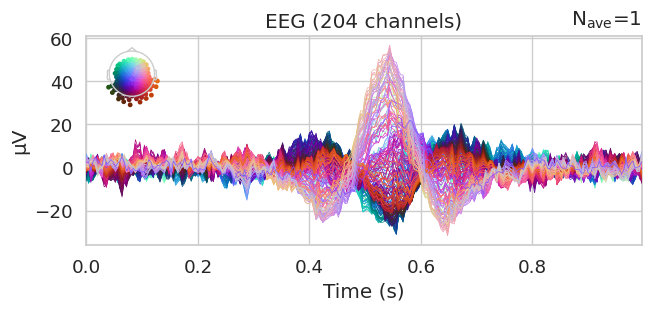

In [38]:
_ = eeg.plot()

## Perform Source Reconstruction

In [49]:
win_size = None

cset    = mm.cset(eeg=eeg, fwd=data["fwd"], cst=data["cst"], lam=0.01, dw=0.5, win_size=win_size, sub=sub)
sloreta = mm.sloreta(eeg=eeg, fwd=data["fwd"], lam=0.01, win_size=win_size)

EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:384: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


#### 🌟 Source Reconstruction

In [52]:
recon = cset 
phase = 0

plotter = mm.viz.plot_resection(data["fwd"]["src"],area, cras=data["cras"], signal=np.abs(recon.data[:,0]), show_max=True)
plotter.show()

Widget(value='<iframe src="http://localhost:44449/index.html?ui=P_0x77972f9e4ec0_30&reconnect=auto" class="pyv…

## Evaluate Performance

In [13]:
dist, corr = compute_error(cset, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
print(f"CSET error: {dist*1000} [mm] and {corr}")

dist, corr = compute_error(sloreta, area, data["fwd"]["src"], brain ,eeg, cras=data["cras"])
print(f"sLORETA error: {dist*1000} [mm] and {corr}")

CSET error: 0.472512527533491 [mm] and 0.48242078285930223
sLORETA error: 0.25798142029415777 [mm] and 0.3826644357367487
